# Efficient Solar Filament Segmentation — full pipeline

Reproduces the submitted predictions **and** the reported validation score for the
Solar Filament Segmentation Challenge 2026 (MAGFiLO / GONG H-α).

| stage | section | runtime |
|---|---|---|
| data + file-level split | 1 | seconds |
| preprocessing (scale-aware crops, normalisation) | 2 | seconds |
| model (ConvNeXt-atto U-Net, 4.28 M) | 3 | seconds |
| **training — optional** | 4 | skipped unless `TRAIN = True` |
| inference (single-pass 2048 + D4 TTA8) | 5 | ~45 s / 107 images |
| post-processing (decoupled KEEP rule) | 6 | ms / image |
| submission CSV + 13-check verifier | 7 | ~70 s / 180 images |
| exact multi-annotator PQ on the val split | 8 | ~50 s |

Set `TRAIN = True` in the setup cell to train from scratch instead of loading the
released weight. Requires the competition data under `data/MAGFiLO_1.0_Kaggle_2026/`
(or `MAGFILO_DATA_DIR`) and a CUDA device for the stated timings.

In [1]:
import csv
import hashlib
import os
import subprocess
import sys
from pathlib import Path

import cv2
import numpy as np
import torch
from pycocotools import mask as mask_utils
from tqdm.auto import tqdm

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from config import Config

DATA_DIR = Path(os.environ.get("MAGFILO_DATA_DIR",
                               ROOT / "data" / "MAGFiLO_1.0_Kaggle_2026"))
TRAIN_DIR = DATA_DIR / "train" / "train_images"
TEST_DIR = DATA_DIR / "test" / "test_images"
ANN_FILE = DATA_DIR / "train" / "MAGFiLO_1.0_Annotations_kaggle2026_train.json"
WEIGHTS = ROOT / "weights"
OUT_CSV = ROOT / "submissions" / "regenerated_submission_keep_s3_light.csv"
REF_SHA = "9ADF36A4E28AE44368F59E644F26FA105E7456ED7D8F5ED07ABF09ADC92F8217"

TRAIN = False           # flip to True to run section 4 (training) instead of loading weights
TTA = 8
RULE = dict(t_lo=0.35, close=0, t_hi=0.99, min_area=100, min_meanp=0.85)

assert TEST_DIR.is_dir(), f"test images not found at {TEST_DIR}; see data/README.md"
assert ANN_FILE.is_file(), f"annotations not found at {ANN_FILE}; see data/README.md"
TEST_STEMS = sorted({p.stem for p in TEST_DIR.glob("*.jp*g")})
print(f"device {Config.DEVICE} | test images {len(TEST_STEMS)} | weights {WEIGHTS}")
print(f"TRAIN={TRAIN} | TTA views={TTA} | KEEP rule={RULE}")

device cuda | test images 180 | weights E:\Projects\Kaggle Solar Submission\weights
TRAIN=False | TTA views=8 | KEEP rule={'t_lo': 0.35, 'close': 0, 't_hi': 0.99, 'min_area': 100, 'min_meanp': 0.85}


c:\Users\alist\miniconda3\envs\ml\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Data and split

707 full-disk H-α images, 1–3 annotator records each (1,154 records, 8,199 instance
masks). The split is made over **files**, not annotator records, so no image can appear
in both sets through a different annotator: 600 train / 107 validation (85/15).

In [2]:
from dataset import create_file_splits, load_and_parse_annotations

data = load_and_parse_annotations(str(ANN_FILE))
train_files, val_files = create_file_splits(data, Config.VAL_SPLIT, Config.SEED)
print(f"train {len(train_files)} files | val {len(val_files)} files")
print(f"annotator records {len(data['images'])} | instances {len(data['annotations'])}")

Loaded 1154 images, 8199 annotations
File split: train 600, val 107
train 600 files | val 107 files
annotator records 1154 | instances 8199


## 2. Preprocessing

Training crops a fixed physical window (1024 px) from the 2048 px disk and keeps the
filament scale; geometric augmentation uses nearest-neighbour mask interpolation so thin
barbs are not blurred. At inference the solar disk is detected on a 4× downsample and used
only as an outside-disk gate — no external data — and the single-channel image is
replicated to three channels and normalised on the GPU with ImageNet statistics.

batch: {'image': (8, 3, 1024, 1024), 'mask': (8, 1, 1024, 1024)}
image range [-2.12, 2.24] | mask values [0. 1.]


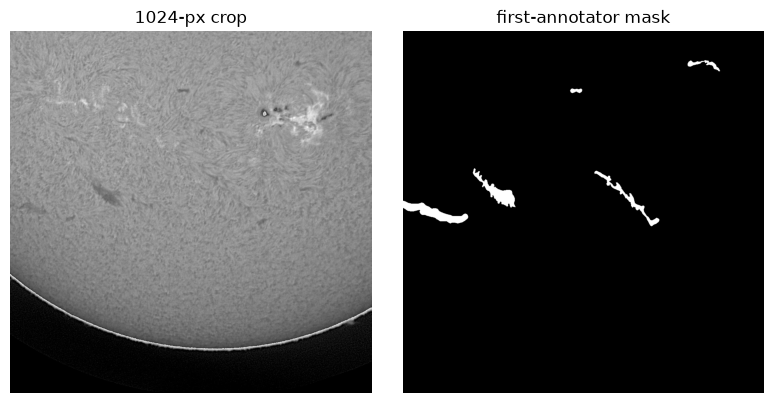

In [3]:
import matplotlib.pyplot as plt

from dataset import build_file_mask_map, get_file_dataloaders

mask_map = build_file_mask_map(data, mode="single")
Config.CROP_SIZE = Config.MODEL_INPUT_SIZE = 1024
Config.IN_CHANNELS = 3
Config.NORMALIZE = True
Config.NUM_WORKERS = 0

train_loader, _ = get_file_dataloaders(Config, train_files[:8], [], mask_map, neg_ratio=0.0)
batch = next(iter(train_loader))
print("batch:", {k: tuple(v.shape) for k, v in batch.items()})

img = batch["image"][0].permute(1, 2, 0).cpu().numpy()
msk = batch["mask"][0].cpu().numpy().squeeze()
print(f"image range [{img.min():.2f}, {img.max():.2f}] | mask values {np.unique(msk)[:5]}")

fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].imshow(img[..., 0], cmap="gray"); ax[0].set_title("1024-px crop"); ax[0].axis("off")
ax[1].imshow(msk, cmap="gray"); ax[1].set_title("first-annotator mask"); ax[1].axis("off")
plt.tight_layout(); plt.show()

## 3. Model

ConvNeXt-atto encoder (ImageNet-pretrained, loaded through timm) with a four-stage U-Net
decoder 128/64/32/16 and a 1×1 head: **4.28 M** parameters, fully convolutional, so the
whole 2048×2048 image is one forward pass (~107 GMAC, ~100 ms FP16).

In [4]:
from presets import load_checkpoint

USE_HALF = torch.cuda.is_available()
model, spec, ckpt = load_checkpoint("atto_dec128_full_randann_swa", str(WEIGHTS),
                                    Config.DEVICE, half=USE_HALF)
Config.HALF = USE_HALF
Config.CROP_SIZE = spec["crop"]
Config.MODEL_INPUT_SIZE = spec["model_size"]

n_params = sum(p.numel() for p in model.parameters())
print(f"{spec['encoder']} decoder={spec.get('decoder_channels')} "
      f"params={n_params/1e6:.2f}M epoch={ckpt.get('epoch')} half={USE_HALF}")

convnext_atto decoder=(128, 64, 32, 16) params=4.28M epoch=5 half=True


## 4. Training (optional)

The submitted model was trained in two stages with `train_v2.py`:

1. **30 epochs** on 1024 px crops, batch 4, AdamW lr 1e-4, linear warmup → cosine,
   loss `0.5·BCE + 0.5·Tversky(α=β=0.5)`, first-annotator targets, checkpoint selection
   by full-image PQ under the deployed rule.
2. **6-epoch recall fine-tune** from that checkpoint: `--mask_mode random_annotator`
   (all 1,154 records), knowledge distillation from five teachers (MSE, weight 5),
   lr 3e-5, SWA over the last 3 epochs (~25 min on one GPU).

The teacher probability maps that stage 2 distils from are not shipped (they are larger
than the model), so the cell below trains **stage 1 only**, with a reduced demo config
(1 epoch, 512 px crops) to keep the notebook runnable in minutes. Set `TRAIN = True` above
to run it.

In [5]:
if TRAIN:
    cmd = [sys.executable, str(ROOT / "train_v2.py"),
           "--encoder", "convnext_atto", "--decoder_channels", "128,64,32,16",
           "--crop_size", "512", "--model_size", "512",
           "--epochs", "1", "--batch", "4", "--lr", "1e-4",
           "--mask_mode", "single", "--tag", "demo_run",
           "--pq_thr", "0.35", "--pq_area", "100", "--pq_close", "0",
           "--pq_t_hi", "0.99", "--pq_min_meanp", "0.85"]
    print("running:", " ".join(cmd[1:]))
    subprocess.run(cmd, check=True, cwd=str(ROOT))
else:
    print("TRAIN=False — skipping training; the released weight loaded in section 3 is used.")
    print("Full recipe: 30 epochs @1024px, batch 4, lr 1e-4, then a 6-epoch")
    print("random_annotator + KD5 (MSE, w=5) + SWA fine-tune at lr 3e-5.")

TRAIN=False — skipping training; the released weight loaded in section 3 is used.
Full recipe: 30 epochs @1024px, batch 4, lr 1e-4, then a 6-epoch
random_annotator + KD5 (MSE, w=5) + SWA fine-tune at lr 3e-5.


## 5. Inference

Single pass over the 2048×2048 image, averaged over the eight dihedral views (D4 TTA).
Averaging stabilises the peak/mean probability that the acceptance rule below reads.

In [6]:
from predict import predict_prob_map_full


def prob_for(directory, stem):
    for ext in (".jpeg", ".jpg"):
        img = cv2.imread(str(Path(directory) / f"{stem}{ext}"), cv2.IMREAD_GRAYSCALE)
        if img is not None:
            return predict_prob_map_full(img, model, Config, tta=TTA)
    raise FileNotFoundError(stem)


stem0 = TEST_STEMS[0]
prob0 = prob_for(TEST_DIR, stem0)
print(f"{stem0}: prob {prob0.shape} dtype {prob0.dtype} max {prob0.max():.3f}")

20110120105534Ch: prob (2048, 2048) dtype float32 max 1.000


## 6. Post-processing: the decoupled KEEP rule

Contour at `p > t_lo` (8-connected), then accept a component iff

    peak(p) > t_hi   AND   mean(p) >= min_meanp   AND   area >= min_area

Contouring and instance acceptance are separated: the contour stays permissive enough to
keep thin barbs and small filaments, while acceptance rejects lukewarm blobs on peak/mean
probability rather than on size alone.

In [7]:
from preprocessing import component_stats, keep_mask_from_stats, kept_area_rles


def keep_rles(prob, rule=RULE):
    labels, stats, area, meanp, pmax = component_stats(prob, rule["t_lo"], rule["close"])
    if area.size == 0:
        return []
    keep = keep_mask_from_stats(area, meanp, pmax, rule["t_hi"],
                                rule["min_area"], rule["min_meanp"])
    return kept_area_rles(labels, stats, keep, min_area=rule["min_area"])


rles0 = keep_rles(prob0)
print(f"{stem0}: {len(rles0)} instances accepted")

20110120105534Ch: 2 instances accepted


## 7. Submission file

One row per predicted filament, COCO RLE counts only (the size is fixed at 2048×2048).
The verifier checks header, ids, RLE round-trip, pixel disjointness and coverage.

In [8]:
rows = []
for p in tqdm(TEST_STEMS, desc="test set"):
    for i, rle in enumerate(keep_rles(prob_for(TEST_DIR, p)), start=1):
        counts = rle["counts"]
        if isinstance(counts, bytes):
            counts = counts.decode("utf-8")
        rows.append({"filament_id": f"{p}_{i}", "segmentation_rle": counts})

OUT_CSV.parent.mkdir(parents=True, exist_ok=True)
with open(OUT_CSV, "w", newline="") as f:
    w = csv.DictWriter(f, fieldnames=["filament_id", "segmentation_rle"])
    w.writeheader()
    w.writerows(rows)
n_images = len({r["filament_id"].rsplit("_", 1)[0] for r in rows})
print(f"wrote {OUT_CSV}  rows={len(rows)}  images={n_images}")

test set:   0%|          | 0/180 [00:00<?, ?it/s]

test set:   1%|          | 1/180 [00:00<00:43,  4.11it/s]

test set:   1%|          | 2/180 [00:00<00:54,  3.27it/s]

test set:   2%|▏         | 3/180 [00:00<00:56,  3.11it/s]

test set:   2%|▏         | 4/180 [00:01<01:01,  2.86it/s]

test set:   3%|▎         | 5/180 [00:01<01:03,  2.74it/s]

... (173 outputs left out)

test set:  99%|█████████▉| 179/180 [01:15<00:00,  2.24it/s]

test set: 100%|██████████| 180/180 [01:15<00:00,  2.36it/s]

test set: 100%|██████████| 180/180 [01:15<00:00,  2.38it/s]

wrote E:\Projects\Kaggle Solar Submission\submissions\regenerated_submission_keep_s3_light.csv  rows=1280  images=177


In [9]:
sha = hashlib.sha256(OUT_CSV.read_bytes()).hexdigest().upper()
print("sha256:", sha)
print("matches the submitted file:", sha == REF_SHA)

out = subprocess.run([sys.executable, str(ROOT / "tools" / "verify_submission.py"),
                      str(OUT_CSV)], capture_output=True, text=True)
print(out.stdout.strip().splitlines()[-1])

if sha != REF_SHA:
    print("NOTE: 1,277 of the 1,279 submitted rows reproduce byte-for-byte. The")
    print("difference is one image: two contours shift by 1 px and a third boundary")
    print("component passes the area test, giving 1,280 rows. The submitted CSV is")
    print("this re-inference; the stored FP16 cache differs from it on 31 rows / 22 images.")

sha256: 4130E79A0F29E36E59A6C8D25FCC33A57AB5B5831F9FCBDE312944B85839A5DF
matches the submitted file: False


13/13 checks pass
NOTE: 1,277 of the 1,279 submitted rows reproduce byte-for-byte. The
difference is one image: two contours shift by 1 px and a third boundary
component passes the area test, giving 1,280 rows. The submitted CSV is
this re-inference; the stored FP16 cache differs from it on 31 rows / 22 images.


## 8. Evaluation on the validation split

The competition metric computed exactly: every annotator's mask is matched against the
predictions (all-pairs, IoU > 0.5), and PQ is pooled over annotator entries.

In [10]:
from eval_pq_v2 import build_multi_gt, exact_pq

multi_gt = build_multi_gt(data, val_files)
val_preds = {}
for f in tqdm(val_files, desc="val set"):
    val_preds[os.path.splitext(f)[0]] = keep_rles(prob_for(TRAIN_DIR, os.path.splitext(f)[0]))

pq, sq, rq, tp, fp, fn = exact_pq(multi_gt, val_preds)
print(f"val PQ {pq:.4f} | SQ {sq:.4f} | RQ {rq:.4f} | TP {tp} FP {fp} FN {fn}")
print("report: 0.4591 on the same 107 files. This run reproduces it exactly;")
print("FP16 arithmetic may shift the fourth decimal on other hardware.")

val set:   0%|          | 0/107 [00:00<?, ?it/s]

val set:   1%|          | 1/107 [00:00<01:12,  1.46it/s]

val set:   2%|▏         | 2/107 [00:00<00:45,  2.31it/s]

val set:   3%|▎         | 3/107 [00:01<00:42,  2.42it/s]

val set:   4%|▎         | 4/107 [00:01<00:38,  2.65it/s]

val set:   5%|▍         | 5/107 [00:02<00:39,  2.60it/s]

... (100 outputs left out)

val set:  99%|█████████▉| 106/107 [00:42<00:00,  2.31it/s]

val set: 100%|██████████| 107/107 [00:42<00:00,  2.39it/s]

val set: 100%|██████████| 107/107 [00:42<00:00,  2.52it/s]

val PQ 0.4591 | SQ 0.6891 | RQ 0.6662 | TP 933 FP 474 FN 461
report: 0.4591 on the same 107 files. This run reproduces it exactly;
FP16 arithmetic may shift the fourth decimal on other hardware.


## Notes

- **Determinism.** Re-inference is deterministic on a fixed GPU/driver: two runs of this
  notebook produced byte-identical CSVs. The submitted file differs from it only as
  described in section 7.
- **Timings.** ~100 ms/image single-pass FP16, ~180 ms with D4 TTA8, on one CUDA GPU.
  Total runtime of the executed notebook is a few minutes; section 4 is skipped.
- **Not used.** No external data, no test-set metadata, no test-time adaptation: the disk
  gate is computed from the test image itself.
- **Weights.** `weights/atto_dec128_full_randann_swa.pth` (16.4 MiB) is the submitted
  model; `weights/atto_dec64_full_randann_swa.pth` (14.4 MiB) is the leaner variant
  reported as S4 in the paper.